# Prediksi IHSG (^JKSE)

Notebook ini memprediksi **penutupan IHSG untuk hari bursa berikutnya** lalu membuat **proyeksi 20 hari bursa ke depan**.

Alur:
1. Ambil data historis `^JKSE` dari Yahoo Finance (di-cache ke `ihsg_raw.csv`).
2. Feature engineering dari OHLCV: return & lag, moving average, RSI, volatilitas, volume, efek hari bursa.
3. Bandingkan baseline (**random walk** & **drift**) dengan 3 model ML memakai `TimeSeriesSplit` di data train.
4. Evaluasi pada holdout ±2 tahun terakhir: MAE, RMSE, MAPE, dan hit rate arah.
5. Forecast rekursif 20 hari bursa + rentang ketidakpastian, disimpan ke `ihsg_forecast.csv`.

> IHSG harian hampir random walk: baseline "besok = harga hari ini" sangat sulit dikalahkan.
> Notebook ini sengaja menampilkan perbandingan jujur model vs baseline, jadi jangan kaget kalau selisihnya kecil
> atau model kalah. Hasilnya 

## 0. Setup

In [ ]:
import warnings

warnings.filterwarnings("ignore")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

RANDOM_STATE = 42
TICKER = "^JKSE"      
START = "2010-01-01"  
TEST_DAYS = 500       
HORIZON = 20          
CACHE = Path("ihsg_raw.csv")

## 1. Ambil data IHSG

In [ ]:
def load_ihsg(ticker=TICKER, start=START, cache=CACHE, refresh=False):
    """Unduh OHLCV IHSG, atau pakai cache CSV kalau masih segar (<= 5 hari)."""
    if cache.exists() and not refresh:
        cached = pd.read_csv(cache, index_col=0, parse_dates=True).sort_index()
        if cached.index.max() >= pd.Timestamp.today().normalize() - pd.Timedelta(days=5):
            print(f"Memakai cache {cache.name} ({len(cached)} baris)")
            return cached

    raw = yf.download(ticker, start=start, auto_adjust=False, progress=False)
    if raw.empty:
        raise RuntimeError(
            "Gagal mengunduh data. Cek koneksi internet, atau taruh CSV OHLCV di "
            f"{cache} lalu panggil load_ihsg(refresh=False)."
        )
    if isinstance(raw.columns, pd.MultiIndex): 
        raw.columns = raw.columns.get_level_values(0)

    df = raw.rename(columns={"Adj Close": "Adj_Close"})[
        ["Open", "High", "Low", "Close", "Adj_Close", "Volume"]
    ].copy()
    df.index = pd.to_datetime(df.index).tz_localize(None).normalize()
    df = df[df["Volume"] > 0]                     
    df = df[~df.index.duplicated(keep="last")].dropna()
    df.to_csv(cache)
    print(f"Data diunduh: {len(df)} baris -> {cache.name}")
    return df


px = load_ihsg(refresh=True)  
print(f"Periode: {px.index.min():%d %b %Y} s/d {px.index.max():%d %b %Y} | {len(px)} hari bursa")
px.tail()

Data diunduh: 4071 baris -> ihsg_raw.csv
Periode: 04 Jan 2010 s/d 26 Oct 2026 | 4071 hari bursa


Price,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
2026-10-20,4980.163086,5278.888184,4980.163086,5278.888184,5278.888184,534990700
2026-10-21,5310.848145,5328.359863,5185.359863,5328.359863,5328.359863,292010300
2026-10-22,5247.979004,5422.586914,5185.526855,5387.904785,5387.904785,356924900
2026-10-23,5397.336914,5455.210938,5366.293945,5439.257812,5439.257812,397036500
2026-10-26,5442.299805,5453.646973,5349.753906,5373.094238,5373.094238,280027100


## 2. Sekilas data

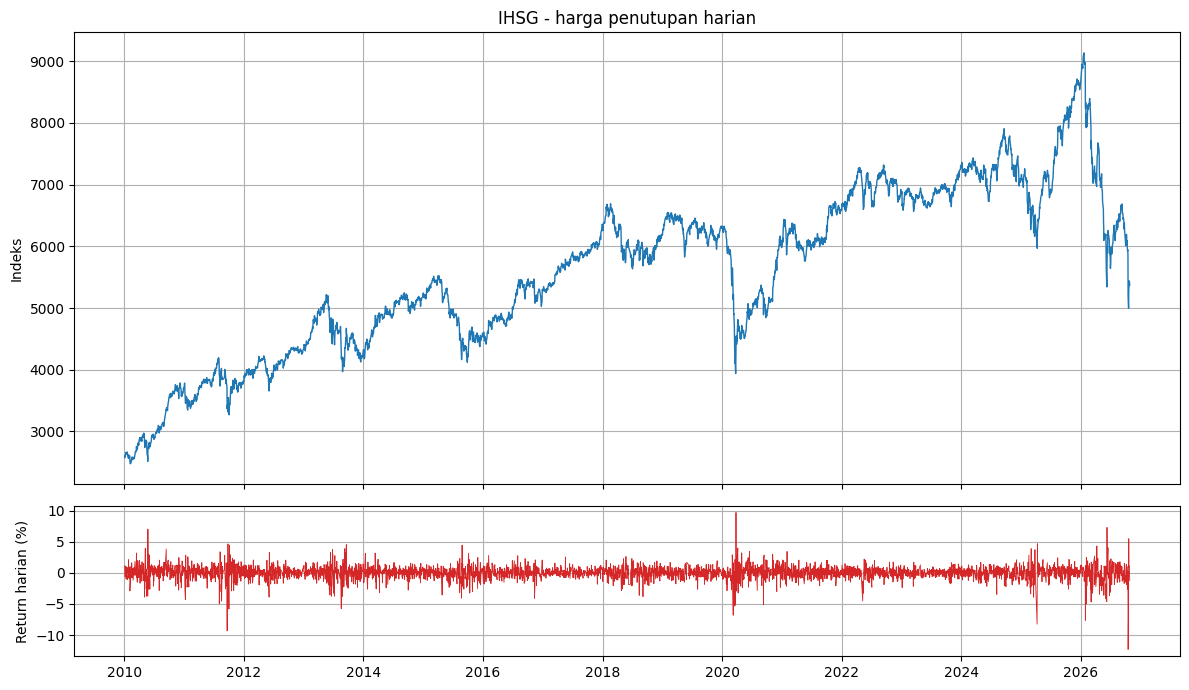

count    4071.00
mean     5584.70
std      1324.67
min      2475.57
25%      4579.32
50%      5760.58
75%      6633.91
max      9134.70
Name: Close, dtype: float64

Rata-rata return harian : 0.0181%
Volatilitas harian      : 1.1142%
Return harian terburuk  : -12.30% (16 Oct 2026)


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(px.index, px["Close"], lw=1.0, color="tab:blue")
axes[0].set_title("IHSG - harga penutupan harian")
axes[0].set_ylabel("Indeks")
axes[1].plot(px.index, np.log(px["Close"]).diff() * 100, lw=0.6, color="tab:red")
axes[1].set_ylabel("Return harian (%)")
plt.tight_layout()
plt.show()

log_ret = np.log(px["Close"]).diff().dropna()
print(px["Close"].describe().round(2))
print(f"\nRata-rata return harian : {log_ret.mean() * 100:.4f}%")
print(f"Volatilitas harian      : {log_ret.std() * 100:.4f}%")
print(f"Return harian terburuk  : {log_ret.min() * 100:.2f}% ({log_ret.idxmin():%d %b %Y})")

## 3. Feature engineering

Model memprediksi **return log sesi berikutnya** (`y_ret`), bukan harga mentah, karena return jauh lebih stasioner.
Harga prediksi direkonstruksi dengan `Close_t * exp(pred_ret)`. Kolom `y_close` = harga penutupan sesi berikutnya,
dipakai sebagai pembanding saat evaluasi.

In [ ]:
def rsi(close, window=14):
    """Relative Strength Index sederhana (rata-rata gain/loss)."""
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(window).mean()
    loss = (-delta.clip(upper=0)).rolling(window).mean()
    return 100 - 100 / (1 + gain / loss)


FEATURES = [
    "ret", "ret_lag1", "ret_lag2", "ret_lag3", "ret_lag4", "ret_lag5",
    "close_ma20", "ma5_ma20", "ma20_ma60",
    "vol20", "rsi14", "intraday", "gap", "vol_z",
    "mon", "tue", "wed", "thu",
]


def make_features(price, with_target=True):
    """Hitung fitur teknikal per hari.

    with_target=True  -> tambahkan y_ret / y_close (sesi berikutnya) untuk training.
    with_target=False -> hanya fitur, dipakai saat forecast.
    """
    d = price.copy()

    d["ret"] = np.log(d["Close"]).diff()
    for lag in (1, 2, 3, 4, 5):
        d[f"ret_lag{lag}"] = d["ret"].shift(lag)

    d["ma5"] = d["Close"].rolling(5).mean()
    d["ma20"] = d["Close"].rolling(20).mean()
    d["ma60"] = d["Close"].rolling(60).mean()
    d["close_ma20"] = d["Close"] / d["ma20"] - 1   
    d["ma5_ma20"] = d["ma5"] / d["ma20"] - 1
    d["ma20_ma60"] = d["ma20"] / d["ma60"] - 1

    d["vol20"] = d["ret"].rolling(20).std()        
    d["rsi14"] = rsi(d["Close"], 14)
    d["intraday"] = (d["High"] - d["Low"]) / d["Close"]
    d["gap"] = d["Open"] / d["Close"].shift(1) - 1
    vmean = d["Volume"].rolling(20).mean()
    vstd = d["Volume"].rolling(20).std()
    d["vol_z"] = (d["Volume"] - vmean) / vstd

    for i, name in enumerate(["mon", "tue", "wed", "thu"]):  
        d[name] = (d.index.dayofweek == i).astype(int)

    if with_target:
        d["y_ret"] = d["ret"].shift(-1)
        d["y_close"] = d["Close"].shift(-1)
        d = d.dropna()
    else:
        d = d.dropna(subset=FEATURES)
    return d


data = make_features(px)
print(f"{len(data)} baris siap dilatih | {len(FEATURES)} fitur")
data[["Close", "y_close", "y_ret"] + FEATURES[:6]].tail()

4011 baris siap dilatih | 18 fitur


Price,Close,y_close,y_ret,ret,ret_lag1,ret_lag2,ret_lag3,ret_lag4,ret_lag5
Date,,,,,,,,,
2026-10-19,4996.608887,5278.888184,0.054956,-0.037031,-0.123004,-0.013424,0.002873,-0.001715,-0.026205
2026-10-20,5278.888184,5328.359863,0.009328,0.054956,-0.037031,-0.123004,-0.013424,0.002873,-0.001715
2026-10-21,5328.359863,5387.904785,0.011113,0.009328,0.054956,-0.037031,-0.123004,-0.013424,0.002873
2026-10-22,5387.904785,5439.257812,0.009486,0.011113,0.009328,0.054956,-0.037031,-0.123004,-0.013424
2026-10-23,5439.257812,5373.094238,-0.012239,0.009486,0.011113,0.009328,0.054956,-0.037031,-0.123004


## 4. Split train / test (kronologis, tanpa shuffle)

In [5]:
train, test = data.iloc[:-TEST_DAYS], data.iloc[-TEST_DAYS:]
print(f"Train: {train.index.min():%d %b %Y} - {train.index.max():%d %b %Y} ({len(train)} hari)")
print(f"Test : {test.index.min():%d %b %Y} - {test.index.max():%d %b %Y} ({len(test)} hari)")
print(f"Porsi hari naik -> train {np.mean(train['y_ret'] > 0):.1%}, test {np.mean(test['y_ret'] > 0):.1%}")

X_train, y_train = train[FEATURES], train["y_ret"]
X_test = test[FEATURES]

Train: 30 Mar 2010 - 17 Sep 2024 (3511 hari)
Test : 18 Sep 2024 - 23 Oct 2026 (500 hari)
Porsi hari naik -> train 54.5%, test 50.0%


## 5. Pilih model dengan validasi berjalan (TimeSeriesSplit)

Data time series tidak boleh di-*shuffle*, jadi validasi memakai `TimeSeriesSplit`: tiap fold melatih pada masa lalu
dan menguji pada blok sesudahnya. Model terbaik = RMSE return terkecil di CV, **bukan** di data test.

In [6]:
MODELS = {
    "Ridge": Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Random Forest": RandomForestRegressor(
        n_estimators=400, min_samples_leaf=20, max_features=0.5,
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_depth=3,
        l2_regularization=1.0, random_state=RANDOM_STATE,
    ),
}

cv = TimeSeriesSplit(n_splits=5)
cv_scores = {}
for name, model in MODELS.items():
    fold_rmse = []
    for tr_idx, va_idx in cv.split(X_train):
        m = clone(model).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        pred = m.predict(X_train.iloc[va_idx])
        fold_rmse.append(np.sqrt(np.mean((y_train.iloc[va_idx] - pred) ** 2)))
    cv_scores[name] = float(np.mean(fold_rmse))

pd.Series(cv_scores, name="CV RMSE (return)").sort_values().to_frame().round(6)

,CV RMSE (return)
Random Forest,0.009692
Ridge,0.009779
Hist Gradient Boosting,0.010135


In [7]:
best_name = min(cv_scores, key=cv_scores.get)
best_model = clone(MODELS[best_name]).fit(X_train, y_train)
print(f"Model terpilih: {best_name} (CV RMSE {cv_scores[best_name]:.6f})")

Model terpilih: Random Forest (CV RMSE 0.009692)


## 6. Evaluasi pada holdout

Semua prediksi dibandingkan dengan `y_close` (penutupan sesi berikutnya). Dua baseline:
* Naive ialah prediksi besok = harga hari ini (random walk).
* Drift ialah prediksi besok = harga hari ini × rata-rata return train.

`Hit rate arah` = persentase tebakan naik/turun yang benar. Prediksi return >= 0 dianggap "naik",
sehingga baseline naive (prediksi return 0) selalu menebak naik dan hit rate-nya = porsi hari naik di data test.

In [8]:
def evaluate(pred_ret, close_t, actual_close, actual_ret, label):
    pred_price = close_t * np.exp(np.asarray(pred_ret))
    err = actual_close - pred_price
    return {
        "Model": label,
        "MAE (poin)": np.mean(np.abs(err)),
        "RMSE (poin)": np.sqrt(np.mean(err ** 2)),
        "MAPE (%)": np.mean(np.abs(err / actual_close)) * 100,
        "Hit rate arah (%)": np.mean((np.asarray(pred_ret) >= 0) == (actual_ret > 0)) * 100,
    }


close_t = test["Close"].to_numpy()
actual_close = test["y_close"].to_numpy()
actual_ret = test["y_ret"].to_numpy()

rows = [
    evaluate(np.zeros_like(actual_ret), close_t, actual_close, actual_ret,
             "1. Naive (besok = hari ini)"),
    evaluate(np.full_like(actual_ret, y_train.mean()), close_t, actual_close, actual_ret,
             "2. Drift (rata-rata return train)"),
]
for name, model in MODELS.items():
    pred_ret = clone(model).fit(X_train, y_train).predict(X_test)
    rows.append(evaluate(pred_ret, close_t, actual_close, actual_ret, name))

results = pd.DataFrame(rows).set_index("Model").round(2)
results

,MAE (poin),RMSE (poin),MAPE (%),Hit rate arah (%)
Model,,,,
1. Naive (besok = hari ini),71.88,103.71,1.04,50.0
2. Drift (rata-rata return train),71.91,103.84,1.04,50.0
Ridge,72.31,104.67,1.04,50.6
Random Forest,72.17,104.70,1.04,52.6
Hist Gradient Boosting,73.95,106.18,1.06,50.4


In [ ]:
naive_rmse = results.loc["1. Naive (besok = hari ini)", "RMSE (poin)"]
model_rmse = results.loc[best_name, "RMSE (poin)"]
print(f"RMSE {best_name:<24}: {model_rmse:>8.2f} poin")
print(f"RMSE naive (random walk)      : {naive_rmse:>8.2f} poin")
print(f"Rata-rata pergerakan harian   : {np.mean(np.abs(np.diff(np.r_[close_t[0], actual_close]))):>8.2f} poin")
if model_rmse < naive_rmse:
    print(f"\n=> Model mengalahkan baseline sebesar {naive_rmse - model_rmse:.2f} poin RMSE.")
else:
    print(f"\n Model BELUM mengalahkan baseline (selisih {model_rmse - naive_rmse:+.2f} poin RMSE).")
    print("   Wajar untuk indeks harian: informasi return kemarin hampir tidak membantu menebak return besok.")

RMSE Random Forest           :   104.70 poin
RMSE naive (random walk)      :   103.71 poin
Rata-rata pergerakan harian   :    71.88 poin

=> Model BELUM mengalahkan baseline (selisih +0.99 poin RMSE).
   Wajar untuk indeks harian: informasi return kemarin hampir tidak membantu menebak return besok.


## 7. Visual holdout

Karena model memprediksi *perubahan*, garis prediksi akan menempel dekat harga hari sebelumnya - itu perilaku
yang benar, bukan bug. Yang menentukan adalah error dan hit rate pada tabel di atas.

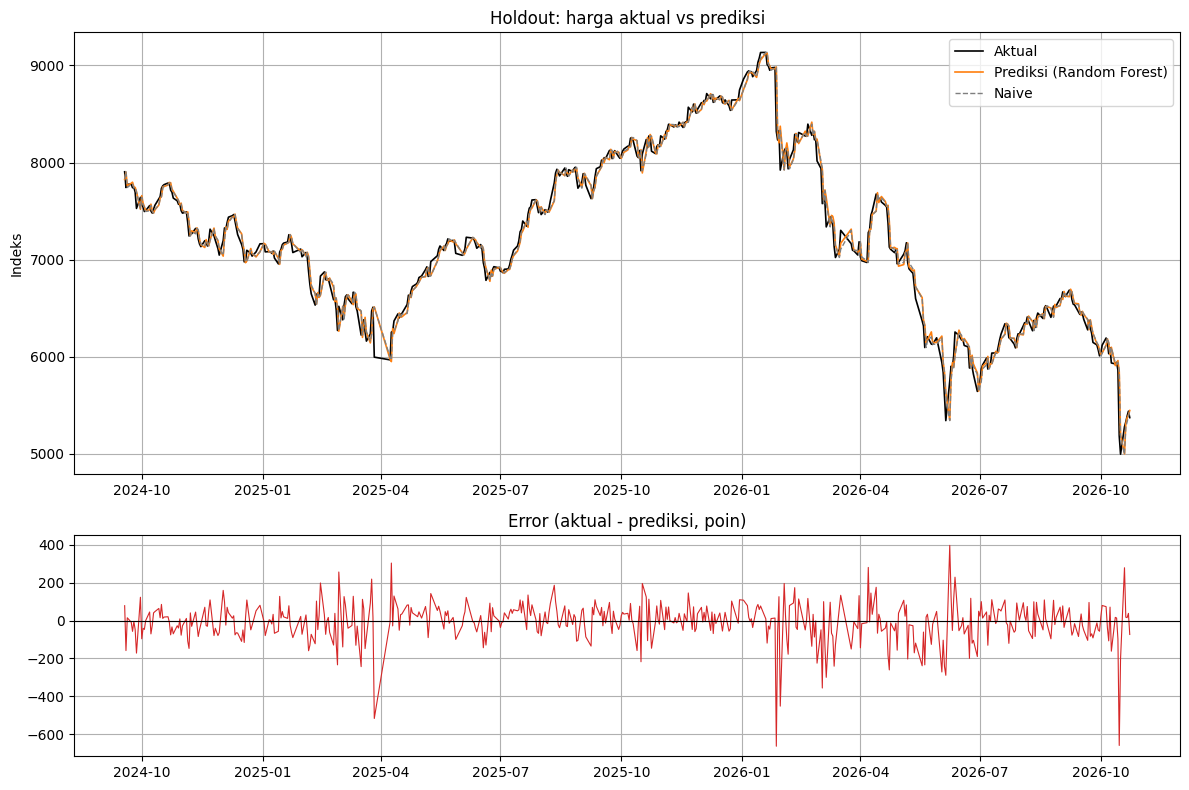

,aktual,prediksi
Date,,
2026-10-19,5278.89,4999.69
2026-10-20,5328.36,5310.53
2026-10-21,5387.90,5372.30
2026-10-22,5439.26,5401.11
2026-10-23,5373.09,5446.49


In [10]:
pred_price = close_t * np.exp(best_model.predict(X_test))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(test.index, actual_close, label="Aktual", lw=1.2, color="black")
axes[0].plot(test.index, pred_price, label=f"Prediksi ({best_name})", lw=1.2, color="tab:orange")
axes[0].plot(test.index, close_t, label="Naive", lw=1.0, ls="--", color="tab:gray")
axes[0].set_title("Holdout: harga aktual vs prediksi")
axes[0].set_ylabel("Indeks")
axes[0].legend()

axes[1].plot(test.index, actual_close - pred_price, lw=0.8, color="tab:red")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Error (aktual - prediksi, poin)")
plt.tight_layout()
plt.show()

pd.DataFrame({"aktual": actual_close, "prediksi": pred_price},
             index=test.index).tail().round(2)

## 8. Proyeksi 20 hari bursa ke depan

Model dilatih ulang pada **seluruh** data, lalu dipakai secara rekursif: hasil prediksi hari ke-1 dimasukkan kembali
sebagai input untuk hari ke-2, dan seterusnya (fitur MA/RSI/volatilitas ikut dihitung ulang).
Rentang memakai simpangan baku residual holdout yang melebar seiring akar horizon - perkiraan kasar, bukan interval
prediksi yang ketat. Proyeksi yang hampir lurus biasanya berasal dari bias drift model, bukan dari sinyal kuat:
cocokkan dengan tabel evaluasi di bagian 6 sebelum menafsirkan angkanya.

In [ ]:
RESID_SIGMA = float(np.std(actual_ret - best_model.predict(X_test)))

def forecast_path(model, price, horizon=HORIZON):
    """Iterasi prediksi satu hari ke depan, fitur dihitung ulang tiap langkah."""
    hist = price.copy()
    out = []
    for step in range(1, horizon + 1):
        feats = make_features(hist, with_target=False).iloc[[-1]]
        r = float(model.predict(feats[FEATURES])[0])
        next_close = float(hist["Close"].iloc[-1]) * np.exp(r)
        next_date = hist.index[-1] + pd.offsets.BDay(1)
        hist.loc[next_date] = {
            "Open": next_close, "High": next_close, "Low": next_close,
            "Close": next_close, "Adj_Close": next_close,
            "Volume": float(hist["Volume"].tail(20).mean()),
        }
        out.append({
            "tanggal": next_date,
            "pred_close": next_close,
            "pred_ret (%)": r * 100,
            "batas_bawah": next_close * np.exp(-1.96 * RESID_SIGMA * np.sqrt(step)),
            "batas_atas": next_close * np.exp(1.96 * RESID_SIGMA * np.sqrt(step)),
        })
    return pd.DataFrame(out).set_index("tanggal")

final_model = clone(MODELS[best_name]).fit(data[FEATURES], data["y_ret"])
forecast = forecast_path(final_model, px)
forecast.round(2)

,pred_close,pred_ret (%),batas_bawah,batas_atas
tanggal,,,,
2026-10-27,5366.33,-0.13,5205.71,5531.91
2026-10-28,5352.68,-0.25,5127.52,5587.72
2026-10-29,5360.40,0.14,5085.56,5650.10
2026-10-30,5370.92,0.20,5054.22,5707.47
2026-11-02,5377.28,0.12,5024.04,5755.36
2026-11-03,5393.57,0.30,5006.68,5810.36
2026-11-04,5411.36,0.33,4993.32,5864.39
2026-11-05,5435.84,0.45,4988.14,5923.71
2026-11-06,5453.71,0.33,4978.52,5974.26


Tersimpan: ihsg_forecast.csv (20 baris)


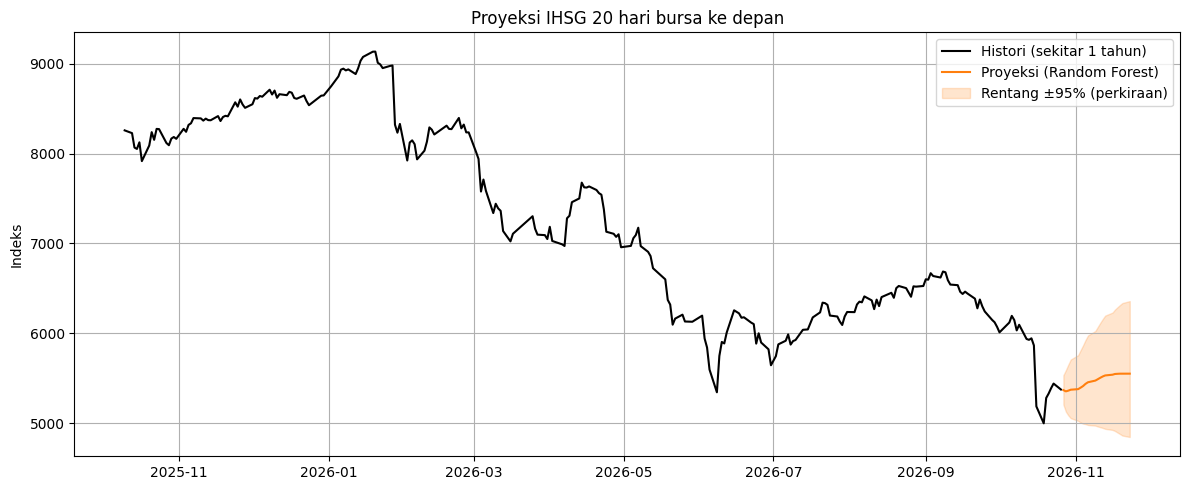

Harga terakhir (26 Oct 2026): 5,373.09
Proyeksi H+20 (23 Nov 2026): 5,549.57 (+3.28%)


In [12]:
forecast.to_csv("ihsg_forecast.csv")
print(f"Tersimpan: ihsg_forecast.csv ({len(forecast)} baris)")

recent = px["Close"].tail(250)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(recent.index, recent.values, label="Histori (sekitar 1 tahun)", color="black")
ax.plot(forecast.index, forecast["pred_close"], label=f"Proyeksi ({best_name})", color="tab:orange")
ax.fill_between(forecast.index, forecast["batas_bawah"], forecast["batas_atas"],
                color="tab:orange", alpha=0.2, label="Rentang ±95% (perkiraan)")
ax.set_title(f"Proyeksi IHSG {HORIZON} hari bursa ke depan")
ax.set_ylabel("Indeks")
ax.legend()
plt.tight_layout()
plt.show()

last_close = px["Close"].iloc[-1]
print(f"Harga terakhir ({px.index[-1]:%d %b %Y}): {last_close:,.2f}")
print(f"Proyeksi H+{HORIZON} ({forecast.index[-1]:%d %b %Y}): {forecast['pred_close'].iloc[-1]:,.2f} "
      f"({forecast['pred_close'].iloc[-1] / last_close - 1:+.2%})")

## 9. Catatan & kemungkinan pengembangan

**Kenapa hasilnya biasa saja?** Return indeks harian hampir tidak punya autokorelasi; sebagian besar sinyal yang
"terlihat" di plot adalah level harga, bukan informasi prediktif. Baseline random walk karena itu sulit dikalahkan,
dan model yang terlihat hebat biasanya bocor data (look-ahead).

**Yang belum ada di notebook ini** (butuh paket tambahan):

| Ide | Paket | Catatan |
|---|---|---|
| ARIMA / SARIMA / GARCH | `statsmodels` (belum terpasang) | baseline statistik untuk return & volatilitas |
| LSTM / GRU | `tensorflow` atau `torch` | butuh data & tuning jauh lebih banyak |
| Sentimen berita / media sosial | `transformers`, scraping | sinyal alternatif, kualitas data jadi isu utama |
| Fitur makro (USD/IDR, BI rate, harga komoditas, indeks sektoral) | `yfinance` / API BI | biasanya lebih informatif daripada fitur harga murni |

**Kalau mau horizon lain:** ubah `HORIZON`. Untuk prediksi mingguan/bulanan, prediksi return multi-hari
(`Close.shift(-5)`) biasanya memberi sinyal lebih kuat daripada harian.

**Sebelum dipakai serius:** refit berkala (walk-forward), uji stabilitas antar periode, dan bandingkan selalu
dengan baseline naive. Semua angka di notebook ini bukan saran investasi.